In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (33538, 65)


C:\Users\Gnanasri\AppData\Local\Temp\ipykernel_16728\3663527280.py:4: DtypeWarning: Columns (30) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/train.csv")


In [3]:
# Create a fresh working copy of the original dataset
df_clean = df.copy()

# Check the shape before preparation
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (33538, 65)
Working dataset shape: (33538, 65)


In [4]:
# Calculate missing-value percentages
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

# Display columns with missing values
missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_summary.round(2))

                             Missing Values  Missing Percentage
host_acceptance_rate                  33538              100.00
square_feet                           33197               98.98
notes                                 20093               59.91
host_response_rate                    16193               48.28
host_response_time                    16193               48.28
interaction                           14880               44.37
access                                14234               42.44
neighborhood_overview                 13590               40.52
house_rules                           13555               40.42
host_about                            13164               39.25
transit                               12742               37.99
space                                 10500               31.31
review_scores_value                    7711               22.99
review_scores_checkin                  7709               22.99
review_scores_location                 7

In [5]:
# Identify columns with more than 90% missing values
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

high_missing_columns = missing_percentage[
    missing_percentage > 90
].index.tolist()

print("Columns with more than 90% missing values:")
print(high_missing_columns)

Columns with more than 90% missing values:
['host_acceptance_rate', 'square_feet']


In [6]:
# Remove columns with excessive missing values
columns_to_drop = ["host_acceptance_rate", "square_feet"]

df_clean = df_clean.drop(columns=columns_to_drop)

# Verify the changes
print("Original dataset shape:", df.shape)
print("Prepared dataset shape:", df_clean.shape)

print("Removed columns:", columns_to_drop)

Original dataset shape: (33538, 65)
Prepared dataset shape: (33538, 63)
Removed columns: ['host_acceptance_rate', 'square_feet']


In [7]:
# Identify columns with only one unique non-missing value
constant_columns = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=True) <= 1
]

print("Constant or entirely missing columns:", constant_columns)

Constant or entirely missing columns: ['experiences_offered', 'is_business_travel_ready']


In [8]:
# Remove columns with no useful variation
constant_columns = [
    "experiences_offered",
    "is_business_travel_ready"
]

df_clean = df_clean.drop(columns=constant_columns)

# Verify the changes
print("Original dataset shape:", df.shape)
print("Current working dataset shape:", df_clean.shape)
print("Removed columns:", constant_columns)

Original dataset shape: (33538, 65)
Current working dataset shape: (33538, 61)
Removed columns: ['experiences_offered', 'is_business_travel_ready']


In [9]:
# Count complete duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# Check for zero and negative prices
zero_prices = (df_clean["price"] == 0).sum()
negative_prices = (df_clean["price"] < 0).sum()

print("Listings with zero price:", zero_prices)
print("Listings with negative price:", negative_prices)

Listings with zero price: 16
Listings with negative price: 0


In [11]:
# Remove listings with zero or negative prices
df_clean = df_clean[df_clean["price"] > 0].copy()

# Verify the changes
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print("Remaining zero-price listings:", (df_clean["price"] == 0).sum())
print("Remaining negative-price listings:", (df_clean["price"] < 0).sum())

Original dataset shape: (33538, 65)
Working dataset shape: (33522, 61)
Remaining zero-price listings: 0
Remaining negative-price listings: 0


In [12]:
# Summarize missing values after the previous preparation steps
missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_summary.round(2).to_string())

                             Missing Values  Missing Percentage
notes                                 20084               59.91
host_response_rate                    16187               48.29
host_response_time                    16187               48.29
interaction                           14876               44.38
access                                14229               42.45
neighborhood_overview                 13580               40.51
house_rules                           13546               40.41
host_about                            13160               39.26
transit                               12734               37.99
space                                 10497               31.31
review_scores_value                    7709               23.00
review_scores_checkin                  7707               22.99
review_scores_location                 7706               22.99
review_scores_accuracy                 7692               22.95
review_scores_communication            7

In [13]:
# Check missing values in the target column
print("Missing prices:", df_clean["price"].isnull().sum())

# Check the price data type
print("Price data type:", df_clean["price"].dtype)

# Display basic price statistics
print(df_clean["price"].describe())

Missing prices: 0
Price data type: float64
count    33522.000000
mean       145.246584
std        133.079657
min         10.000000
25%         69.000000
50%        109.000000
75%        175.000000
max       1999.000000
Name: price, dtype: float64


In [14]:
# Display data types of all columns
print(df_clean.dtypes.to_string())

id                                    int64
name                                 object
summary                              object
space                                object
description                          object
neighborhood_overview                object
notes                                object
transit                              object
access                               object
interaction                          object
house_rules                          object
host_id                               int64
host_name                            object
host_since                           object
host_location                        object
host_about                           object
host_response_time                   object
host_response_rate                   object
host_is_superhost                    object
host_neighbourhood                   object
host_listings_count                 float64
host_verifications                   object
host_has_profile_pic            

In [15]:
# Summarize the number of columns by data type
print(df_clean.dtypes.value_counts())

object     40
float64    13
int64       8
Name: count, dtype: int64


In [16]:
# Inspect columns that may need type conversion
columns_to_check = [
    "host_since",
    "first_review",
    "last_review",
    "host_response_rate",
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "price"
]

for col in columns_to_check:
    if col in df_clean.columns:
        print(f"\n--- {col} ---")
        print("Data type:", df_clean[col].dtype)
        print("Sample values:")
        print(df_clean[col].dropna().head(5).tolist())


--- host_since ---
Data type: object
Sample values:
['2012-03-12', '2013-09-14', '2012-12-11', '2013-12-03', '2012-05-11']

--- first_review ---
Data type: object
Sample values:
['2018-01-01', '2014-04-15', '2018-07-26', '2015-01-31', '2016-04-12']

--- last_review ---
Data type: object
Sample values:
['2018-07-03', '2018-10-20', '2018-10-14', '2018-10-17', '2016-07-21']

--- host_response_rate ---
Data type: object
Sample values:
['100%', '100%', '100%', '98%', '100%']

--- host_is_superhost ---
Data type: object
Sample values:
['f', 'f', 'f', 'f', 't']

--- host_has_profile_pic ---
Data type: object
Sample values:
['t', 't', 't', 't', 't']

--- host_identity_verified ---
Data type: object
Sample values:
['t', 't', 't', 't', 't']

--- price ---
Data type: float64
Sample values:
[145.0, 175.0, 180.0, 42.0, 80.0]


In [17]:
# Convert date columns to datetime format
date_columns = ["host_since", "first_review", "last_review"]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# Verify conversions
print(df_clean[date_columns].dtypes)

host_since      datetime64[ns]
first_review    datetime64[ns]
last_review     datetime64[ns]
dtype: object


In [18]:
# Convert host response rate from percentage text to numeric
df_clean["host_response_rate"] = pd.to_numeric(
    df_clean["host_response_rate"].str.replace("%", "", regex=False),
    errors="coerce"
)

# Verify conversion
print("Data type:", df_clean["host_response_rate"].dtype)
print(df_clean["host_response_rate"].head())

Data type: float64
0      NaN
1    100.0
2    100.0
3      NaN
4    100.0
Name: host_response_rate, dtype: float64


In [19]:
# Summarize missing values after the previous preparation steps
missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_summary.round(2).to_string())

                             Missing Values  Missing Percentage
notes                                 20084               59.91
host_response_rate                    16187               48.29
host_response_time                    16187               48.29
interaction                           14876               44.38
access                                14229               42.45
neighborhood_overview                 13580               40.51
house_rules                           13546               40.41
host_about                            13160               39.26
transit                               12734               37.99
space                                 10497               31.31
review_scores_value                    7709               23.00
review_scores_checkin                  7707               22.99
review_scores_location                 7706               22.99
review_scores_accuracy                 7692               22.95
review_scores_communication            7

In [20]:
boolean_columns = [
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "instant_bookable",
    "require_guest_profile_picture",
    "require_guest_phone_verification"
]

for col in boolean_columns:
    if col in df_clean.columns:
        print(f"\n--- {col} ---")
        print(df_clean[col].value_counts(dropna=False))


--- host_is_superhost ---
host_is_superhost
f      27992
t       5525
NaN        5
Name: count, dtype: int64

--- host_has_profile_pic ---
host_has_profile_pic
t      33452
f         65
NaN        5
Name: count, dtype: int64

--- host_identity_verified ---
host_identity_verified
t      16822
f      16695
NaN        5
Name: count, dtype: int64

--- instant_bookable ---
instant_bookable
f    22010
t    11512
Name: count, dtype: int64

--- require_guest_profile_picture ---
require_guest_profile_picture
f    32717
t      805
Name: count, dtype: int64

--- require_guest_phone_verification ---
require_guest_phone_verification
f    32622
t      900
Name: count, dtype: int64


In [21]:
# Identify Boolean-like columns
boolean_columns = [
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "instant_bookable",
    "require_guest_profile_picture",
    "require_guest_phone_verification"
]

# Convert t/f values to True/False
for col in boolean_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].map({
            "t": True,
            "f": False
        }).astype("boolean")

print(df_clean[boolean_columns].dtypes)

host_is_superhost                   boolean
host_has_profile_pic                boolean
host_identity_verified              boolean
instant_bookable                    boolean
require_guest_profile_picture       boolean
require_guest_phone_verification    boolean
dtype: object


In [22]:
for col in boolean_columns:
    if col in df_clean.columns:
        print(f"\n--- {col} ---")
        print(df_clean[col].value_counts(dropna=False))


--- host_is_superhost ---
host_is_superhost
False    27992
True      5525
<NA>         5
Name: count, dtype: Int64

--- host_has_profile_pic ---
host_has_profile_pic
True     33452
False       65
<NA>         5
Name: count, dtype: Int64

--- host_identity_verified ---
host_identity_verified
True     16822
False    16695
<NA>         5
Name: count, dtype: Int64

--- instant_bookable ---
instant_bookable
False    22010
True     11512
Name: count, dtype: Int64

--- require_guest_profile_picture ---
require_guest_profile_picture
False    32717
True       805
Name: count, dtype: Int64

--- require_guest_phone_verification ---
require_guest_phone_verification
False    32622
True       900
Name: count, dtype: Int64


In [23]:
print("Dataset shape:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes.value_counts())

print("\nMissing values in target:")
print(df_clean["price"].isnull().sum())

Dataset shape: (33522, 61)

Data types:
object            30
float64           14
int64              8
boolean            6
datetime64[ns]     3
Name: count, dtype: int64

Missing values in target:
0


In [24]:
# Select numerical columns
numeric_columns = df_clean.select_dtypes(include="number").columns

# Display minimum and maximum values
numeric_summary = pd.DataFrame({
    "Minimum": df_clean[numeric_columns].min(),
    "Maximum": df_clean[numeric_columns].max(),
    "Missing Values": df_clean[numeric_columns].isnull().sum()
})

print(numeric_summary.to_string())

                                Minimum       Maximum  Missing Values
id                              2515.00  2.977318e+07               0
host_id                          283.00  2.240015e+08               0
host_response_rate                 0.00  1.000000e+02           16187
host_listings_count                0.00  2.271000e+03               5
accommodates                       1.00  1.600000e+01               0
bathrooms                          0.00  1.650000e+01              60
bedrooms                           0.00  1.000000e+01              33
beds                               0.00  1.800000e+01              31
price                             10.00  1.999000e+03               0
guests_included                    1.00  1.600000e+01               0
minimum_nights                     1.00  1.250000e+03               0
maximum_nights                     1.00  2.147484e+09               0
number_of_reviews                  0.00  5.570000e+02               0
review_scores_rating

In [25]:
# Inspect the largest maximum_nights values
print(
    df_clean["maximum_nights"]
    .value_counts()
    .sort_index(ascending=False)
    .head(20)
)

maximum_nights
2147483647    1
20000000      2
1000000       1
112000        1
99999         3
60000         1
15000         1
10000         1
9999          7
6000          1
5000          1
4000          2
3020          1
3000          4
2000          6
1825          6
1800          1
1508          1
1365          1
1300          1
Name: count, dtype: int64


In [26]:
# Count listings with maximum_nights above selected thresholds
for limit in [365, 1000, 10000]:
    count = (df_clean["maximum_nights"] > limit).sum()
    print(f"Listings with maximum_nights > {limit}: {count}")

Listings with maximum_nights > 365: 17368
Listings with maximum_nights > 1000: 17037
Listings with maximum_nights > 10000: 10


In [27]:
# Count zero values in important listing attributes
columns_to_check = [
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "guests_included",
    "minimum_nights",
    "maximum_nights"
]

for col in columns_to_check:
    print(
        f"{col}:",
        (df_clean[col] == 0).sum()
    )

accommodates: 0
bathrooms: 60
bedrooms: 3278
beds: 200
guests_included: 0
minimum_nights: 0
maximum_nights: 0


In [ ]:
# Summarize missing values after the previous preparation steps
missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_summary.round(2).to_string())

                             Missing Values  Missing Percentage
notes                                 20084               59.91
host_response_rate                    16187               48.29
host_response_time                    16187               48.29
interaction                           14876               44.38
access                                14229               42.45
neighborhood_overview                 13580               40.51
house_rules                           13546               40.41
host_about                            13160               39.26
transit                               12734               37.99
space                                 10497               31.31
review_scores_value                    7709               23.00
review_scores_checkin                  7707               22.99
review_scores_location                 7706               22.99
review_scores_accuracy                 7692               22.95
review_scores_communication            7

In [28]:
# Inspect listings with zero bathrooms
print("Listings with zero bathrooms:")
print(
    df_clean.loc[
        df_clean["bathrooms"] == 0,
        ["room_type", "property_type", "accommodates",
         "bedrooms", "beds", "bathrooms", "price"]
    ].head(10)
)

# Inspect listings with zero bedrooms
print("\nListings with zero bedrooms:")
print(
    df_clean.loc[
        df_clean["bedrooms"] == 0,
        ["room_type", "property_type", "accommodates",
         "bedrooms", "beds", "bathrooms", "price"]
    ].head(10)
)

# Inspect listings with zero beds
print("\nListings with zero beds:")
print(
    df_clean.loc[
        df_clean["beds"] == 0,
        ["room_type", "property_type", "accommodates",
         "bedrooms", "beds", "bathrooms", "price"]
    ].head(10)
)

Listings with zero bathrooms:
            room_type property_type  accommodates  bedrooms  beds  bathrooms  \
340      Private room         House             2       1.0   1.0        0.0   
1019     Private room         House             4       1.0   2.0        0.0   
1097     Private room     Apartment             1       1.0   1.0        0.0   
1420     Private room     Apartment             3       1.0   2.0        0.0   
2823  Entire home/apt     Camper/RV             2       0.0   1.0        0.0   
3738     Private room     Apartment             2       1.0   1.0        0.0   
4040     Private room     Apartment             2       1.0   1.0        0.0   
4479     Private room     Apartment             2       1.0   1.0        0.0   
4646     Private room     Apartment             2       1.0   3.0        0.0   
4703     Private room     Apartment             1       1.0   1.0        0.0   

      price  
340    48.0  
1019   69.0  
1097   72.0  
1420   70.0  
2823   59.0  
3738 

In [29]:
# Replace zero bathroom values with missing values
df_clean.loc[df_clean["bathrooms"] == 0, "bathrooms"] = np.nan

# Verify the change
print("Zero bathroom values remaining:",
      (df_clean["bathrooms"] == 0).sum())

print("Missing bathroom values:",
      df_clean["bathrooms"].isnull().sum())

Zero bathroom values remaining: 0
Missing bathroom values: 120


In [30]:
# Inspect listings with zero beds
zero_beds = df_clean[df_clean["beds"] == 0]

print("Number of listings with zero beds:", len(zero_beds))

print(
    zero_beds[
        ["room_type", "property_type", "accommodates",
         "bedrooms", "beds", "bathrooms", "price"]
    ].head(15).to_string()
)

Number of listings with zero beds: 200
            room_type       property_type  accommodates  bedrooms  beds  bathrooms  price
37       Private room           Apartment             2       1.0   0.0        1.0  175.0
53       Private room           Apartment             2       1.0   0.0        2.0   55.0
255       Shared room           Apartment             1       1.0   0.0        1.0   60.0
287      Private room               House             2       1.0   0.0        1.0   36.0
452       Shared room           Townhouse             4       1.0   0.0        1.0   74.0
453      Private room           Apartment             1       1.0   0.0        1.0   45.0
684   Entire home/apt           Apartment             2       1.0   0.0        1.0  200.0
703      Private room               House             4       0.0   0.0        1.0   57.0
1154     Private room               House             2       1.0   0.0        2.0   33.0
1221  Entire home/apt           Apartment             2      

In [32]:
df_clean.loc[df_clean["beds"] == 0, "beds"] = np.nan

In [33]:
print("Zero bed values remaining:", (df_clean["beds"] == 0).sum())
print("Missing bed values:", df_clean["beds"].isna().sum())

Zero bed values remaining: 0
Missing bed values: 231


In [34]:
print("Values above 10000:", (df_clean["maximum_nights"] > 10000).sum())

Values above 10000: 10


In [35]:
df_clean.loc[
    df_clean["maximum_nights"] > 10000,
    "maximum_nights"
] = np.nan

In [36]:
print(
    "Values above 10000 remaining:",
    (df_clean["maximum_nights"] > 10000).sum()
)
print("Missing maximum_nights:", df_clean["maximum_nights"].isna().sum())

Values above 10000 remaining: 0
Missing maximum_nights: 10


In [37]:
# Count missing values in each column
missing_summary = df_clean.isnull().sum()

# Display columns that contain missing values
missing_summary = missing_summary[missing_summary > 0].sort_values(
    ascending=False
)

print(missing_summary)
print("\nTotal missing values:", df_clean.isnull().sum().sum())

notes                          20084
host_response_rate             16187
host_response_time             16187
interaction                    14876
access                         14229
neighborhood_overview          13580
house_rules                    13546
host_about                     13160
transit                        12734
space                          10497
review_scores_value             7709
review_scores_checkin           7707
review_scores_location          7706
review_scores_accuracy          7692
review_scores_communication     7687
review_scores_cleanliness       7677
review_scores_rating            7662
reviews_per_month               6946
first_review                    6946
last_review                     6944
host_neighbourhood              4704
summary                         1271
zipcode                          485
description                      308
beds                             231
bathrooms                        120
host_location                    114
m

In [38]:
# Count listings with and without reviews
print("Listings with zero reviews:",
      (df_clean["number_of_reviews"] == 0).sum())

print("Listings with one or more reviews:",
      (df_clean["number_of_reviews"] > 0).sum())

# Compare missing review scores
print("\nMissing review scores:")
print(df_clean[
    ["review_scores_rating",
     "review_scores_cleanliness",
     "review_scores_value"]
].isnull().sum())

Listings with zero reviews: 6890
Listings with one or more reviews: 26632

Missing review scores:
review_scores_rating         7662
review_scores_cleanliness    7677
review_scores_value          7709
dtype: int64


In [39]:
important_columns = [
    "price",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "host_listings_count",
    "minimum_nights",
    "maximum_nights"
]

print(df_clean[important_columns].isnull().sum())

price                    0
accommodates             0
bathrooms              120
bedrooms                33
beds                   231
host_listings_count      5
minimum_nights           0
maximum_nights          10
dtype: int64


In [40]:
print(
    df_clean.loc[
        df_clean["maximum_nights"].isna(),
        [
            "room_type",
            "property_type",
            "accommodates",
            "minimum_nights",
            "maximum_nights",
            "price"
        ]
    ].to_string()
)

             room_type      property_type  accommodates  minimum_nights  maximum_nights   price
4443   Entire home/apt          Apartment             3               1             NaN   172.0
9866      Private room          Apartment             2               5             NaN   120.0
10276     Private room          Apartment             1              30             NaN    65.0
12957     Private room          Apartment             1               1             NaN   100.0
18710  Entire home/apt          Apartment             1               2             NaN   130.0
21162     Private room          Apartment             1               2             NaN   120.0
21508     Private room          Apartment             3              30             NaN   270.0
22819  Entire home/apt          Apartment             3              30             NaN   175.0
24729  Entire home/apt  Bed and breakfast             3              30             NaN   135.0
33344  Entire home/apt               Lof

In [41]:
print("Missing maximum_nights:",
      df_clean["maximum_nights"].isna().sum())

print("Listings remaining:", len(df_clean))

Missing maximum_nights: 10
Listings remaining: 33522


In [42]:
print("Duplicate listing IDs:", df_clean["id"].duplicated().sum())
print("Final current shape:", df_clean.shape)

Duplicate listing IDs: 0
Final current shape: (33522, 61)


In [43]:
# 1. Check the dataset dimensions
print("Dataset shape:", df_clean.shape)

# 2. Check the target variable
print("\nPrice summary:")
print(df_clean["price"].describe())

# 3. Check data types
print("\nData types:")
print(df_clean.dtypes.value_counts())

# 4. Check missing values
print("\nTotal missing values:", df_clean.isnull().sum().sum())

# 5. Confirm the original dataframe is unchanged
print("\nOriginal dataset shape:", df.shape)


Dataset shape: (33522, 61)

Price summary:
count    33522.000000
mean       145.246584
std        133.079657
min         10.000000
25%         69.000000
50%        109.000000
75%        175.000000
max       1999.000000
Name: price, dtype: float64

Data types:
object            30
float64           15
int64              7
boolean            6
datetime64[ns]     3
Name: count, dtype: int64

Total missing values: 227218

Original dataset shape: (33538, 65)


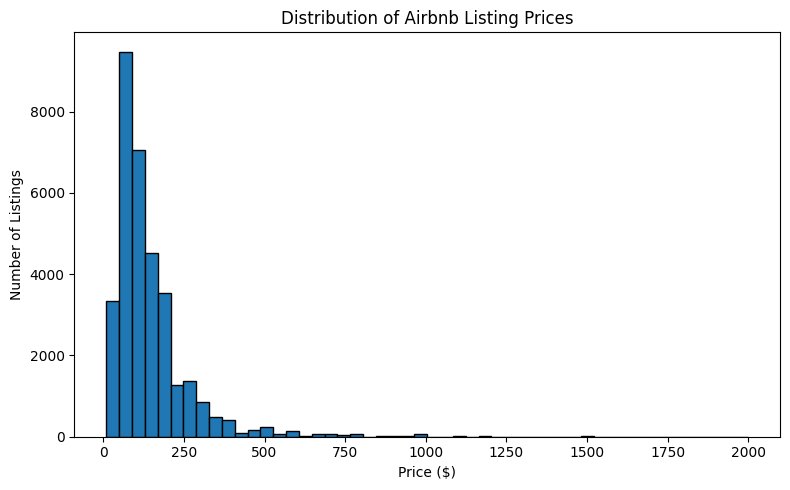

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_clean["price"], bins=50, edgecolor="black")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")
plt.title("Distribution of Airbnb Listing Prices")
plt.tight_layout()
plt.show()

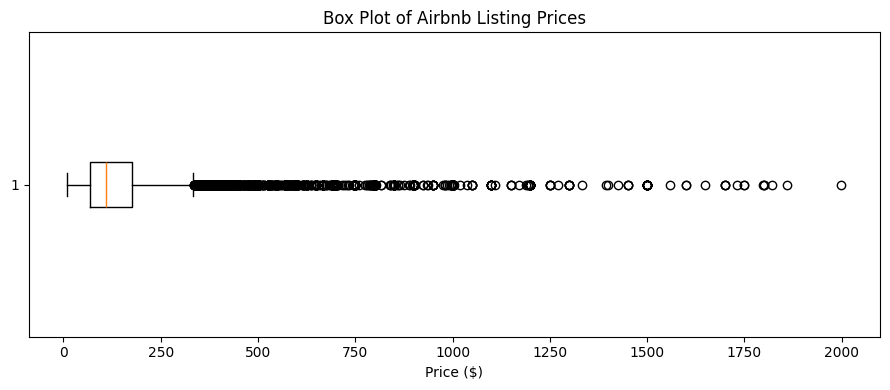

In [45]:
plt.figure(figsize=(9, 4))

plt.boxplot(df_clean["price"], vert=False)

plt.xlabel("Price ($)")
plt.title("Box Plot of Airbnb Listing Prices")

plt.tight_layout()
plt.show()

C:\Users\Gnanasri\AppData\Local\Temp\ipykernel_16728\4230840658.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(prices, labels=room_types)


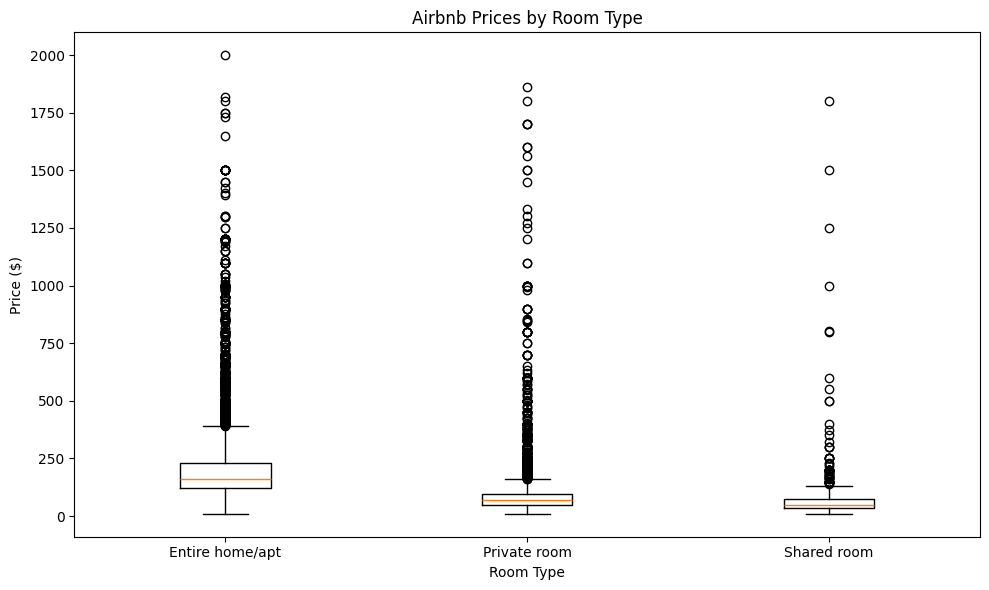

In [46]:
import matplotlib.pyplot as plt

room_types = [
    "Entire home/apt",
    "Private room",
    "Shared room"
]

prices = [
    df_clean.loc[
        df_clean["room_type"] == room,
        "price"
    ].dropna()
    for room in room_types
]

plt.figure(figsize=(10, 6))

plt.boxplot(prices, labels=room_types)

plt.title("Airbnb Prices by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

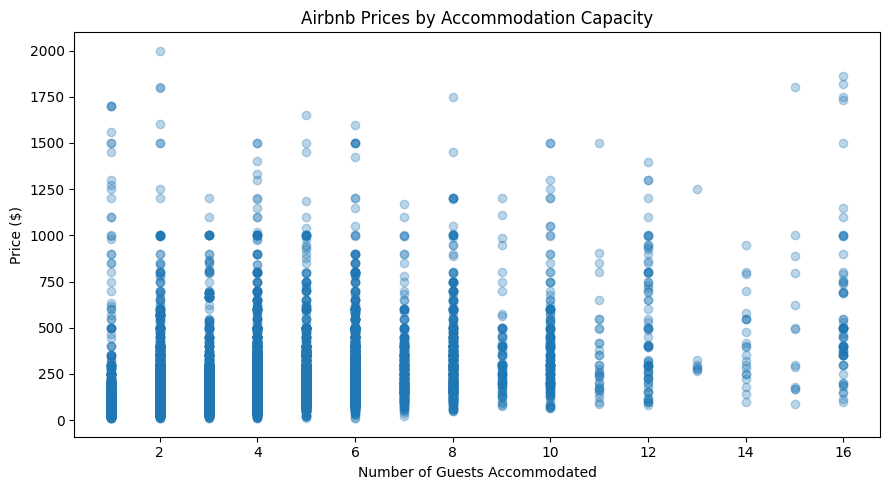

In [47]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["accommodates"],
    df_clean["price"],
    alpha=0.3
)

plt.title("Airbnb Prices by Accommodation Capacity")
plt.xlabel("Number of Guests Accommodated")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

In [48]:
room_price_summary = (
    df_clean.groupby("room_type")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

print(room_price_summary)

                 count    mean  median   min     max
room_type                                           
Entire home/apt  17532  201.09   160.0  10.0  1999.0
Private room     15225   84.54    70.0  10.0  1860.0
Shared room        765   73.62    49.0  10.0  1800.0


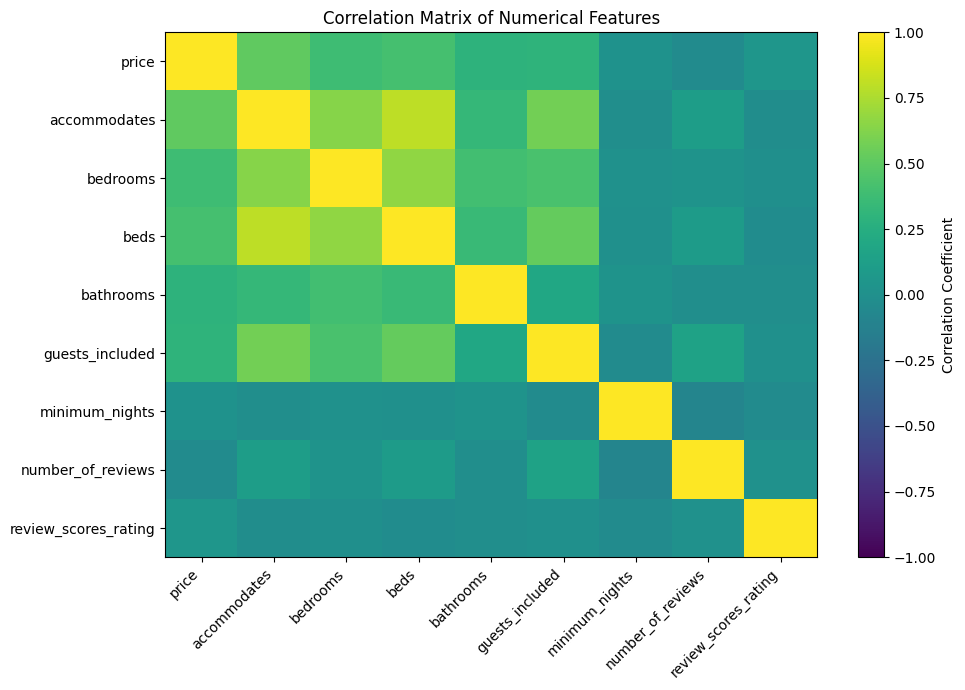

In [49]:
import matplotlib.pyplot as plt

numeric_columns = [
    "price",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "guests_included",
    "minimum_nights",
    "number_of_reviews",
    "review_scores_rating"
]

correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(numeric_columns)), numeric_columns)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [50]:
price_correlations = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(ascending=False)
)

print(price_correlations.round(3))

accommodates            0.513
beds                    0.410
bedrooms                0.382
guests_included         0.303
bathrooms               0.297
review_scores_rating    0.049
minimum_nights          0.019
number_of_reviews      -0.032
Name: price, dtype: float64


In [51]:
location_columns = [
    col for col in df_clean.columns
    if "neighbourhood" in col.lower()
    or "neighborhood" in col.lower()
    or "zipcode" in col.lower()
]

print("Available location columns:")
print(location_columns)

Available location columns:
['neighborhood_overview', 'host_neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'zipcode']


In [52]:
print("Neighbourhood groups:")
print(df_clean["neighbourhood_group_cleansed"].value_counts(dropna=False))

Neighbourhood groups:
neighbourhood_group_cleansed
Manhattan        15441
Brooklyn         13544
Queens            3671
Bronx              652
Staten Island      214
Name: count, dtype: int64


In [53]:
location_price_summary = (
    df_clean.groupby("neighbourhood_group_cleansed")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

print(location_price_summary)

                              count    mean  median
neighbourhood_group_cleansed                       
Manhattan                     15441  184.86   150.0
Brooklyn                      13544  117.67    90.0
Queens                         3671   94.43    75.0
Staten Island                   214  102.27    70.5
Bronx                           652   80.32    65.0


<Figure size 1000x600 with 0 Axes>

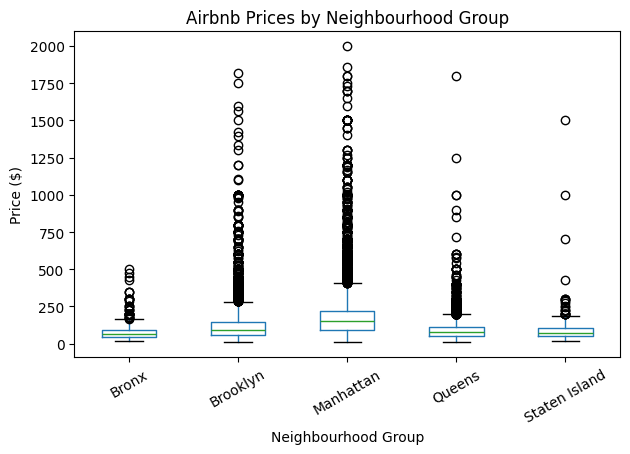

In [54]:
plt.figure(figsize=(10, 6))

df_clean.boxplot(
    column="price",
    by="neighbourhood_group_cleansed",
    grid=False
)

plt.title("Airbnb Prices by Neighbourhood Group")
plt.suptitle("")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Price ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [55]:
bedroom_price_summary = (
    df_clean.groupby("bedrooms")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(bedroom_price_summary)

          count    mean  median
bedrooms                       
0.0        3278  154.97   133.0
1.0       23624  113.50    90.0
2.0        4653  221.66   180.0
3.0        1427  296.77   250.0
4.0         389  403.18   325.0
5.0          87  452.72   398.0
6.0          18  841.56   749.5
7.0           7  594.57   550.0
8.0           3  468.67   499.0
9.0           1  300.00   300.0
10.0          2  847.50   847.5


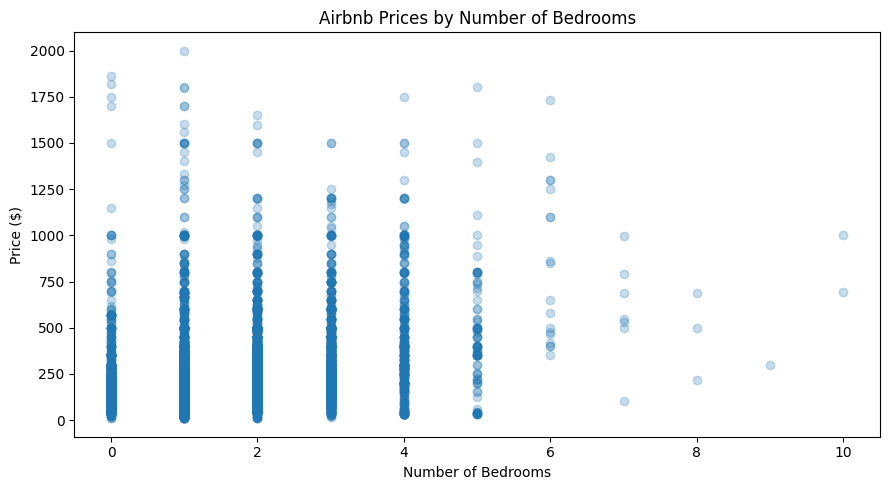

In [56]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["bedrooms"],
    df_clean["price"],
    alpha=0.25
)

plt.title("Airbnb Prices by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price ($)")

plt.tight_layout()
plt.show()

In [57]:
print(
    df_clean["property_type"]
    .value_counts()
    .head(10)
)

property_type
Apartment             27046
House                  2471
Townhouse              1084
Loft                   1035
Condominium             822
Serviced apartment      437
Guest suite             163
Other                    92
Boutique hotel           68
Bed and breakfast        68
Name: count, dtype: int64


In [58]:
top_properties = (
    df_clean["property_type"]
    .value_counts()
    .head(10)
    .index
)

property_price_summary = (
    df_clean[
        df_clean["property_type"].isin(top_properties)
    ]
    .groupby("property_type")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

print(property_price_summary)

                    count    mean  median
property_type                            
Serviced apartment    437  261.50   200.0
Condominium           822  202.03   158.5
Loft                 1035  215.70   150.0
Boutique hotel         68  179.38   135.0
Other                  92  229.36   120.0
Apartment           27046  140.21   110.0
Guest suite           163  112.60    95.0
Townhouse            1084  151.22    95.0
Bed and breakfast      68  111.40    89.0
House                2471  119.35    73.0


In [59]:
# Target variable
target = "price"

# Candidate features for price prediction
candidate_features = [
    "room_type",
    "property_type",
    "neighbourhood_group_cleansed",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "guests_included",
    "minimum_nights",
    "maximum_nights",
    "number_of_reviews",
    "review_scores_rating",
    "reviews_per_month",
    "calculated_host_listings_count",
    "instant_bookable",
    "host_is_superhost"
]

# Keep only columns available in the dataset
features = [
    col for col in candidate_features
    if col in df_clean.columns
]

# Create the target and feature data
X = df_clean[features].copy()
y = df_clean[target].copy()

print("Number of listings:", len(df_clean))
print("Number of features:", len(features))
print("\nSelected features:")
print(features)

print("\nFeature data shape:", X.shape)
print("Target data shape:", y.shape)

Number of listings: 33522
Number of features: 16

Selected features:
['room_type', 'property_type', 'neighbourhood_group_cleansed', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'guests_included', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'review_scores_rating', 'reviews_per_month', 'calculated_host_listings_count', 'instant_bookable', 'host_is_superhost']

Feature data shape: (33522, 16)
Target data shape: (33522,)


In [60]:
print("Feature data types:")
print(X.dtypes)

print("\nMissing values in selected features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Feature data types:
room_type                          object
property_type                      object
neighbourhood_group_cleansed       object
accommodates                        int64
bedrooms                          float64
beds                              float64
bathrooms                         float64
guests_included                     int64
minimum_nights                      int64
maximum_nights                    float64
number_of_reviews                   int64
review_scores_rating              float64
reviews_per_month                 float64
calculated_host_listings_count      int64
instant_bookable                  boolean
host_is_superhost                 boolean
dtype: object

Missing values in selected features:
room_type                            0
property_type                        0
neighbourhood_group_cleansed         0
accommodates                         0
bedrooms                            33
beds                               231
bathrooms             

In [61]:
missing_features = X.isnull().sum()

missing_features = missing_features[missing_features > 0]

print("Features containing missing values:")
print(missing_features.sort_values(ascending=False))

print("\nTotal missing feature values:", X.isnull().sum().sum())

Features containing missing values:
review_scores_rating    7662
reviews_per_month       6946
beds                     231
bathrooms                120
bedrooms                  33
maximum_nights            10
host_is_superhost          5
dtype: int64

Total missing feature values: 15007


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [63]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "bool", "boolean", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['accommodates', 'bedrooms', 'beds', 'bathrooms', 'guests_included', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'review_scores_rating', 'reviews_per_month', 'calculated_host_listings_count']

Categorical features:
['room_type', 'property_type', 'neighbourhood_group_cleansed', 'instant_bookable', 'host_is_superhost']


In [67]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Numerical features: fill missing values with the median
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features: fill missing values, then encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values=np.nan
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Convert nullable Boolean columns to object dtype
X = X.copy()
X["instant_bookable"] = X["instant_bookable"].astype(object)
X["host_is_superhost"] = X["host_is_superhost"].astype(object)

# Replace Pandas <NA> with regular NumPy NaN
X = X.replace({pd.NA: np.nan})

# Rebuild the preprocessor
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor updated successfully!")
print("Remaining missing values in X:", X.isna().sum().sum())

Preprocessor updated successfully!
Remaining missing values in X: 15007


C:\Users\Gnanasri\AppData\Local\Temp\ipykernel_16728\1400422801.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X = X.replace({pd.NA: np.nan})


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (26817, 16)
Testing data: (6705, 16)


In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

linear_model.fit(X_train, y_train)
print("Linear Regression trained successfully!")

random_forest_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Generate predictions on test data
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
def evaluate_model(model_name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    }

# Compare the two trained models
results_df = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

print(results_df.to_string(index=False))

            Model   MAE   RMSE  R2 Score
Linear Regression 56.41 104.20    0.4026
    Random Forest 50.34  97.99    0.4717


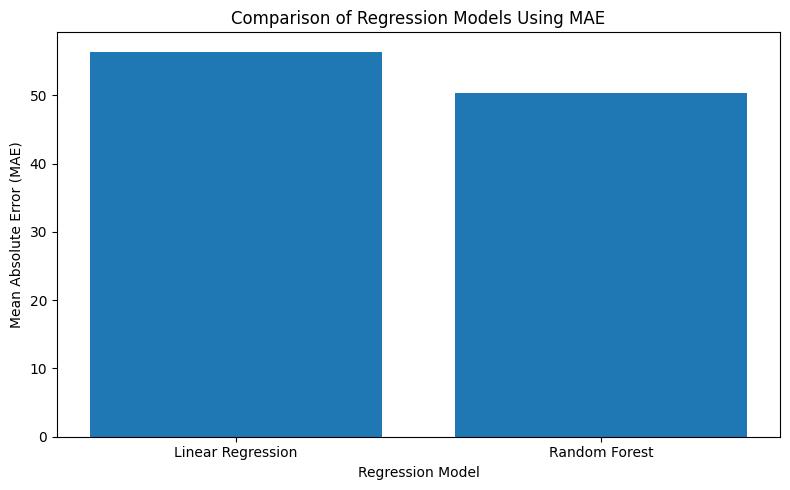

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Comparison of Regression Models Using MAE")
plt.xlabel("Regression Model")
plt.ylabel("Mean Absolute Error (MAE)")
plt.tight_layout()
plt.show()

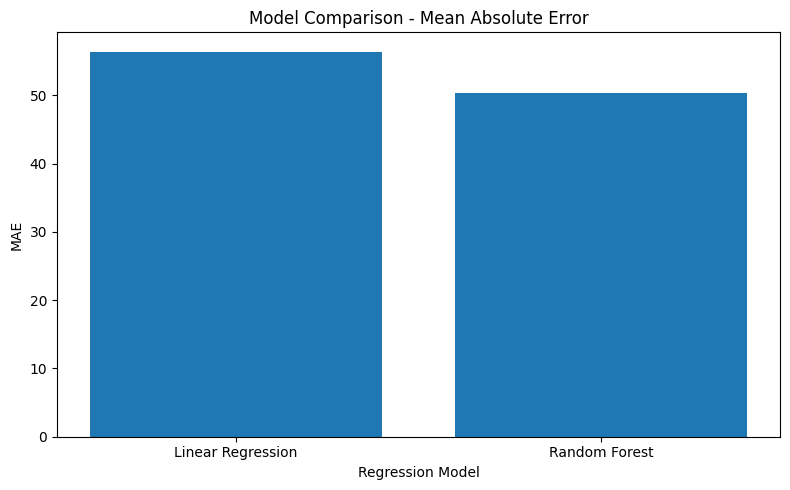

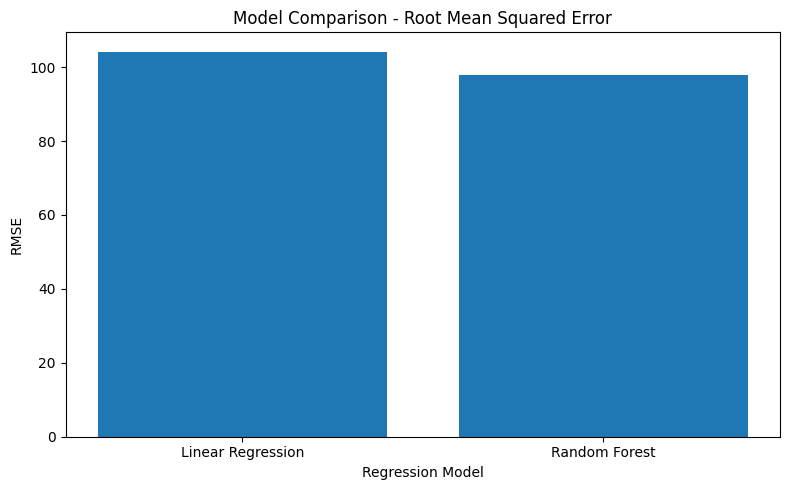

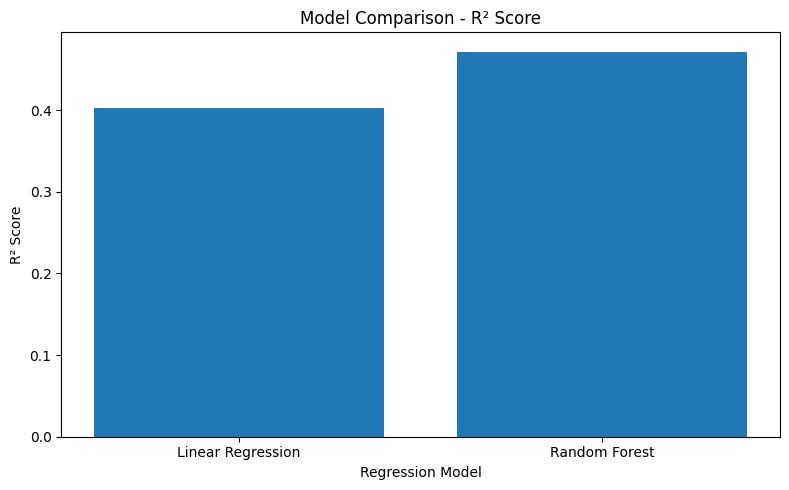

In [72]:
import matplotlib.pyplot as plt

# 1. Compare Mean Absolute Error (MAE)
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Regression Model")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()


# 2. Compare Root Mean Squared Error (RMSE)
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison - Root Mean Squared Error")
plt.xlabel("Regression Model")
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()


# 3. Compare R-squared scores
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("Model Comparison - R² Score")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.tight_layout()
plt.show()

In [73]:
# Create a sample Airbnb listing using the 16 selected features

new_listing = pd.DataFrame([{
    "room_type": "Entire home/apt",
    "property_type": "Apartment",
    "neighbourhood_group_cleansed": "Manhattan",
    "accommodates": 2,
    "bedrooms": 1.0,
    "beds": 1.0,
    "bathrooms": 1.0,
    "guests_included": 1,
    "minimum_nights": 2,
    "maximum_nights": 30,
    "number_of_reviews": 10,
    "review_scores_rating": 95.0,
    "reviews_per_month": 1.5,
    "calculated_host_listings_count": 1,
    "instant_bookable": True,
    "host_is_superhost": True
}])

print("Sample listing details:")
print(new_listing)

Sample listing details:
         room_type property_type neighbourhood_group_cleansed  accommodates  \
0  Entire home/apt     Apartment                    Manhattan             2   

   bedrooms  beds  bathrooms  guests_included  minimum_nights  maximum_nights  \
0       1.0   1.0        1.0                1               2              30   

   number_of_reviews  review_scores_rating  reviews_per_month  \
0                 10                  95.0                1.5   

   calculated_host_listings_count  instant_bookable  host_is_superhost  
0                               1              True               True  


In [74]:
# Predict the listing price using the trained Random Forest model

predicted_price = random_forest_model.predict(new_listing)[0]

print("Predicted Airbnb listing price:", round(predicted_price, 2))

Predicted Airbnb listing price: 170.81


In [75]:
print("=" * 45)
print("AIRBNB LISTING PRICE ANALYZER")
print("=" * 45)

print("Room Type:", new_listing.loc[0, "room_type"])
print("Property Type:", new_listing.loc[0, "property_type"])
print("Neighbourhood:", new_listing.loc[0, "neighbourhood_group_cleansed"])
print("Accommodates:", new_listing.loc[0, "accommodates"])
print("Bedrooms:", new_listing.loc[0, "bedrooms"])

print("-" * 45)
print("Predicted Listing Price:", round(predicted_price, 2))
print("=" * 45)

AIRBNB LISTING PRICE ANALYZER
Room Type: Entire home/apt
Property Type: Apartment
Neighbourhood: Manhattan
Accommodates: 2
Bedrooms: 1.0
---------------------------------------------
Predicted Listing Price: 170.81


In [76]:
def predict_airbnb_price(listing_details):
    """
    Predict the price of an Airbnb listing using the trained Random Forest model.
    """

    # Convert the listing details into a DataFrame
    listing_df = pd.DataFrame([listing_details], columns=X.columns)

    # Predict the listing price
    predicted_price = random_forest_model.predict(listing_df)[0]

    return round(predicted_price, 2)

In [78]:
sample_listing = {
    "room_type": "Entire home/apt",
    "property_type": "Apartment",
    "neighbourhood_group_cleansed": "Manhattan",
    "accommodates": 2,
    "bedrooms": 2.0,
    "beds": 1.0,
    "bathrooms": 1.0,
    "guests_included": 1,
    "minimum_nights": 2,
    "maximum_nights": 30,
    "number_of_reviews": 10,
    "review_scores_rating": 95.0,
    "reviews_per_month": 1.5,
    "calculated_host_listings_count": 1,
    "instant_bookable": True,
    "host_is_superhost": True
}

predicted_price = predict_airbnb_price(sample_listing)

print("Predicted Airbnb listing price:", predicted_price)

Predicted Airbnb listing price: 219.78


In [79]:
print("AIRBNB LISTING PRICE ANALYZER")
print("=" * 50)

print("Dataset shape after cleaning:", df_clean.shape)
print("Average listing price:", round(df_clean["price"].mean(), 2))
print("Median listing price:", round(df_clean["price"].median(), 2))
print("Minimum listing price:", df_clean["price"].min())
print("Maximum listing price:", df_clean["price"].max())

print("\nModels developed:")
print("1. Linear Regression")
print("2. Random Forest Regressor")

print("\nSelected model: Random Forest Regressor")
print("Prediction function: Created and tested successfully")

AIRBNB LISTING PRICE ANALYZER
Dataset shape after cleaning: (33522, 61)
Average listing price: 145.25
Median listing price: 109.0
Minimum listing price: 10.0
Maximum listing price: 1999.0

Models developed:
1. Linear Regression
2. Random Forest Regressor

Selected model: Random Forest Regressor
Prediction function: Created and tested successfully
